## Based on the current distribution of fibers on focalplane, inner and outer radii can be set to 54.0mm and 276.0mm, respectively. --10-26-2026

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.legend_handler import HandlerPatch
import builtins

In [2]:
## estimate field of view
platescale = 128.0    # um/arcsec
r0 = 54.0
r1 = 276.0

deg0 = r0*1.e3/platescale/3600
deg1 = r1*1.e3/platescale/3600
print(deg0, deg1)

FoV = np.pi*(deg1**2 - deg0**2)  # unit: deg^2
print(FoV)

0.1171875 0.5989583333333334
1.08390656366225


In [3]:
dtype = {"names": ("x", "y"),
         "formats": ("f4", "f4")}

df_v2 = np.loadtxt("./science_fibers.txt", dtype=dtype)
df_v2

array([(-253.45786, -67.162544), (-258.65787, -76.169205),
       (-248.25786, -76.169205), ..., ( 253.45786,  79.171425),
       ( 248.25786,  70.164764), ( 258.65787,  70.164764)],
      shape=(2088,), dtype=[('x', '<f4'), ('y', '<f4')])

In [4]:
focal_plane_center_x = np.mean(df_v2["x"])
focal_plane_center_y = np.mean(df_v2["y"])
print(focal_plane_center_x, focal_plane_center_y)

-3.7416187e-06 1.403107e-06


## compare with the previous focalplane

In [5]:
ifile = "/home/zjding/fiberassignment/JUST/modify_focalplane/fiberposcenter.txt"
radius, x_v0, y_v0, x_cen_v0, y_cen_v0 = np.loadtxt(ifile, unpack=True)

In [6]:
df_v1 = pd.read_csv("../v1/fiberpos.csv", names=["radius", "x", "y"])
df_v1

,radius,x,y
0,4.45,-258.725824,-70.184381
1,4.45,-258.725824,-51.887730
2,4.45,-258.725824,-33.591080
3,4.45,-258.725824,-15.294429
4,4.45,-258.725824,3.002221
...,...,...,...
2179,4.45,258.725824,3.002221
2180,4.45,258.725824,21.298872
2181,4.45,258.725824,39.595523
2182,4.45,258.725824,57.892173


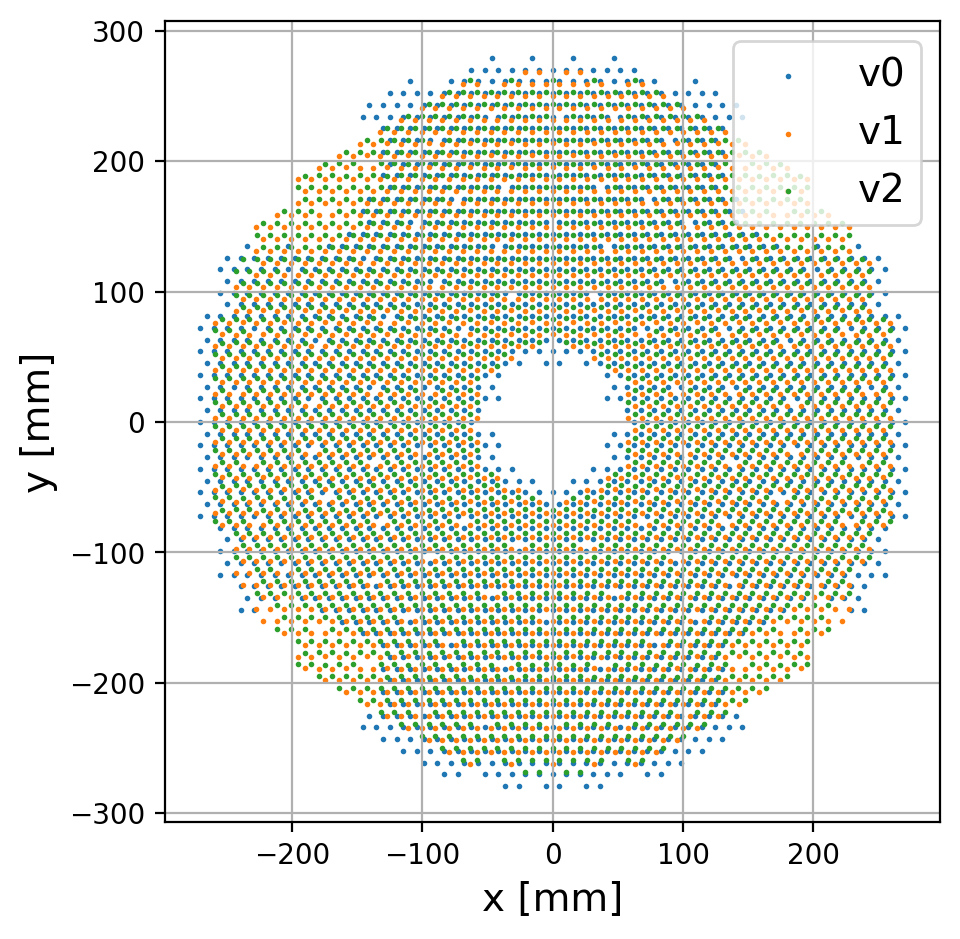

In [7]:
fig, ax = plt.subplots(dpi=200)
ax.scatter(x_cen_v0, y_cen_v0, s=1.0, label='v0')
ax.scatter(df_v1['x'], df_v1['y'], s=1.0, label='v1')
ax.scatter(df_v2['x'], df_v2['y'], s=1.0, label='v2')
ax.set_aspect('equal', adjustable='box') 
ax.set_xlabel("x [mm]", fontsize=14)
ax.set_ylabel("y [mm]", fontsize=14)
ax.legend(fontsize=14)
ax.grid()
plt.tight_layout()

In [8]:
print("old focalplane (v0):")
print("x_max - x_min:", np.max(x_cen_v0) - np.min(x_cen_v0))
print("y_max - y_min:", np.max(y_cen_v0) - np.min(y_cen_v0))

print("old focalplane (v1):")
print("x_max - x_min:", np.max(df_v1["x"]) - np.min(df_v1["x"]))
print("y_max - y_min:", np.max(df_v1["y"]) - np.min(df_v1["y"]))

print("new focalplane (v2):")
print("x_max - x_min:", np.max(df_v2["x"]) - np.min(df_v2["x"]))
print("y_max - y_min:", np.max(df_v2["y"]) - np.min(df_v2["y"]))

old focalplane (v0):
x_max - x_min: 540.8
y_max - y_min: 558.413
old focalplane (v1):
x_max - x_min: 517.451648
y_max - y_min: 530.451523
new focalplane (v2):
x_max - x_min: 517.3262
y_max - y_min: 530.32367


In [9]:
np.min(np.abs(df_v2["y"]))

np.float32(3.002221)

In [10]:
class HandlerCircle(HandlerPatch):
    def create_artists(self, legend, orig_handle,
                       x0, y0, width, height, fontsize, trans):
        # 用内置 min，避免 NumPy 覆盖
        radius = 0.5 * builtins.min(float(width), float(height))
        center = (x0 + width / 2, y0 + height / 2)
        patch = Circle(center, radius)

        self.update_prop(patch, orig_handle, legend)
        patch.set_transform(trans)
        return [patch]

## (0, -3.0) seems the center of the focalplane? No, if we set that, inner circle does not fit well.

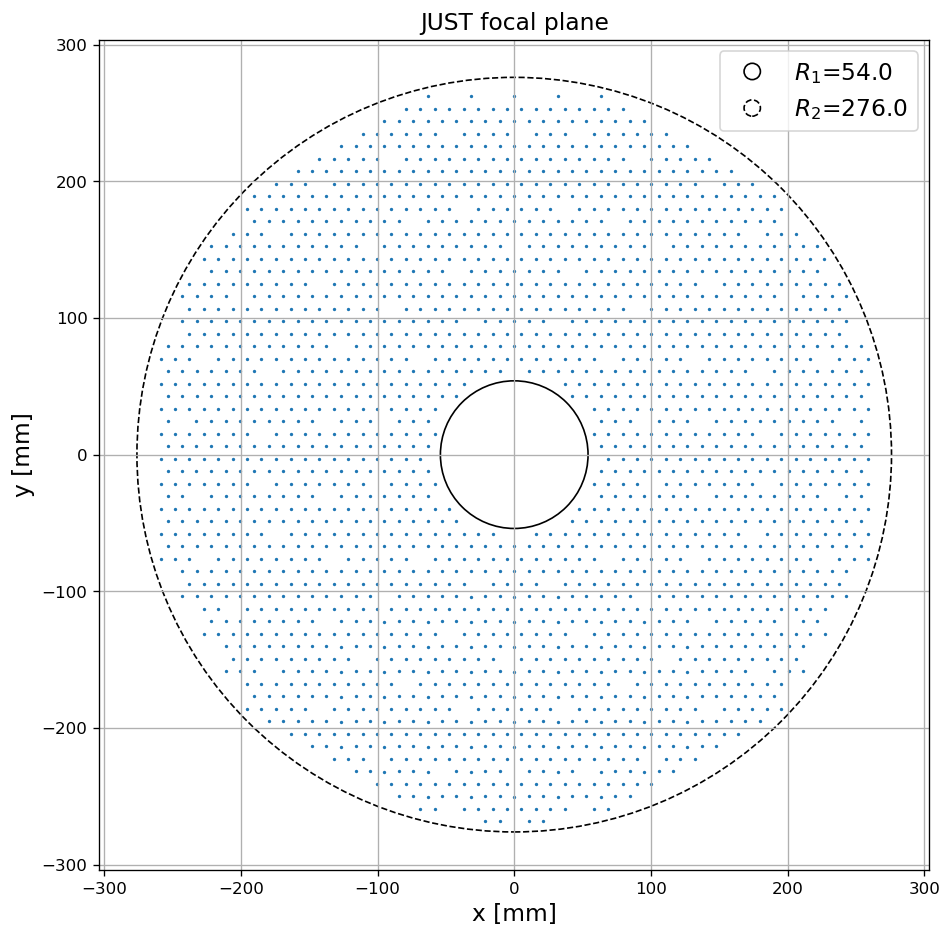

In [11]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.scatter(df_v2["x"], df_v2["y"], s=1.0)

circle1 = Circle((0.0, 0.0), r0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0:.1f}")
circle2 = Circle((0.0, 0.0), r1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={r1:.1f}")

ax.add_patch(circle1)
ax.add_patch(circle2)
ax.set_aspect("equal", adjustable="box") 
ax.set_xlabel("x [mm]", fontsize=14)
ax.set_ylabel("y [mm]", fontsize=14)
#ax.legend(fontsize=14)
ax.legend(handler_map={Circle: HandlerCircle()}, fontsize=14)
ax.set_title("JUST focal plane", fontsize=14)
ax.grid()
plt.tight_layout()
plt.savefig("./just_focalplane_xy.png", bbox_inches="tight")

In [12]:
xmin_id = np.argmin(df_v2["x"])
sel_id = (np.abs(df_v2["x"] - df_v2["x"][xmin_id])<1.e-2)
x_sel, y_sel = df_v2["x"][sel_id], df_v2["y"][sel_id]
print(x_sel, y_sel)

[-258.65787 -258.66013 -258.66177 -258.66275 -258.6631  -258.66275
 -258.66177 -258.66013 -258.65787] [-76.169205 -57.878006 -39.58628  -21.29437   -3.002221  15.289929
  33.581837  51.87356   70.164764]


In [13]:
sel_id = (np.abs(df_v2["x"] - (df_v2["x"][xmin_id]+5.2))<1.e-2)
x_sel_1, y_sel_1 = df_v2["x"][sel_id], df_v2["y"][sel_id]
print(x_sel_1, y_sel_1)

[-253.45786 -253.46014 -253.46178 -253.46275 -253.46307 -253.46275
 -253.46178 -253.46014 -253.45786] [-67.162544 -48.87134  -30.579615 -12.287707   6.004443  24.296593
  42.5885    60.880226  79.171425]


In [14]:
sel_id = (np.abs(df_v2["x"] - (df_v2["x"][xmin_id]+10.4))<1.e-2)
x_sel_2, y_sel_2 = df_v2["x"][sel_id], df_v2["y"][sel_id]
print(x_sel_2, y_sel_2)

[-248.25786 -248.26013 -248.26178 -248.26276 -248.26308 -248.26276
 -248.26178 -248.26013 -248.25786] [-76.169205 -57.878006 -39.58628  -21.29437   -3.002221  15.289929
  33.581837  51.87356   70.164764]


## check whether the left side of the circle covers all the fibers

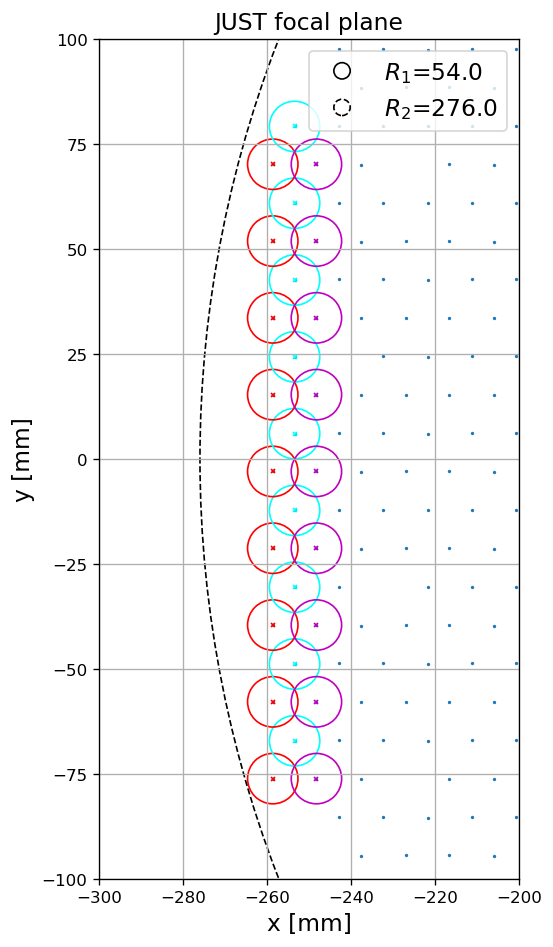

In [15]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.scatter(df_v2["x"], df_v2["y"], s=1.0)

# circle1 = Circle((0.0, -3.0), r0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0:.1f}")
# circle2 = Circle((0.0, -3.0), r1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={r1:.1f}")
circle1 = Circle((0.0, 0.0), r0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0:.1f}")
circle2 = Circle((0.0, 0.0), r1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={r1:.1f}")
ax.plot(x_sel, y_sel, "x", ms=2.5, color="red")
ax.plot(x_sel_1, y_sel_1, "x", ms=2.5, color="cyan")
ax.plot(x_sel_2, y_sel_2, "x", ms=2.5, color="m")

for i in range(len(x_sel)):
    fiber_circle = Circle((x_sel[i], y_sel[i]), 6.0, fill=False, color='red', ls='-', alpha=1.0)
    ax.add_patch(fiber_circle)

    fiber_circle_1 = Circle((x_sel_1[i], y_sel_1[i]), 6.0, fill=False, color='cyan', ls='-', alpha=1.0)
    ax.add_patch(fiber_circle_1)
    fiber_circle_2 = Circle((x_sel_2[i], y_sel_2[i]), 6.0, fill=False, color='m', ls='-', alpha=1.0)
    ax.add_patch(fiber_circle_2)


ax.set_xlim([-300, -200])
ax.set_ylim([-100, 100])

ax.add_patch(circle1)
ax.add_patch(circle2)
ax.set_aspect("equal", adjustable="box") 
ax.set_xlabel("x [mm]", fontsize=14)
ax.set_ylabel("y [mm]", fontsize=14)
#ax.legend(fontsize=14)
ax.legend(handler_map={Circle: HandlerCircle()}, fontsize=14)
ax.set_title("JUST focal plane", fontsize=14)
ax.grid()
plt.tight_layout()

## check the right side of the outer circle

[258.65787 258.66013 258.66177 258.66275 258.6631  258.66275 258.66177
 258.66013 258.65787] [-76.169205 -57.878006 -39.58628  -21.29437   -3.002221  15.289929
  33.581837  51.87356   70.164764]


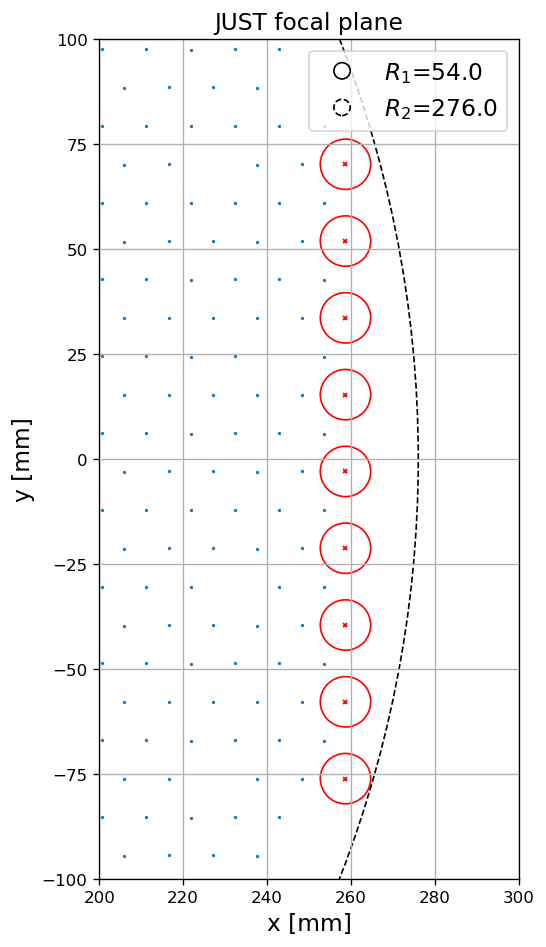

In [16]:
xmax_id = np.argmax(df_v2["x"])
sel_id = (np.abs(df_v2["x"] - df_v2["x"][xmax_id])<1.e-2)
x_sel_right, y_sel_right = df_v2["x"][sel_id], df_v2["y"][sel_id]
print(x_sel_right, y_sel_right)

fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.scatter(df_v2["x"], df_v2["y"], s=1.0)

circle1 = Circle((0.0, 0.0), r0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0:.1f}")
circle2 = Circle((0.0, 0.0), r1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={r1:.1f}")
ax.plot(x_sel_right, y_sel_right, "x", ms=2.5, color="red")
for i in range(len(x_sel_right)):
    fiber_circle = Circle((x_sel_right[i], y_sel_right[i]), 6.0, fill=False, color='red', ls='-', alpha=1.0)
    ax.add_patch(fiber_circle)


ax.set_xlim([200, 300])
ax.set_ylim([-100, 100])

ax.add_patch(circle1)
ax.add_patch(circle2)
ax.set_aspect("equal", adjustable="box") 
ax.set_xlabel("x [mm]", fontsize=14)
ax.set_ylabel("y [mm]", fontsize=14)
#ax.legend(fontsize=14)
ax.legend(handler_map={Circle: HandlerCircle()}, fontsize=14)
ax.set_title("JUST focal plane", fontsize=14)
ax.grid()
plt.tight_layout()

## check the upper part of the outer circle

In [17]:
ymax_id = np.argmax(df_v2["y"])
sel_id = (np.abs(df_v2["y"] - df_v2["y"][ymax_id])<1.e-2)
x_sel_up, y_sel_up = df_v2["x"][sel_id], df_v2["y"][sel_id]
print(x_sel_up, y_sel_up)

[-63.364513 -31.682573   0.        31.682573  63.364513] [262.0889  262.09186 262.09286 262.09186 262.0889 ]


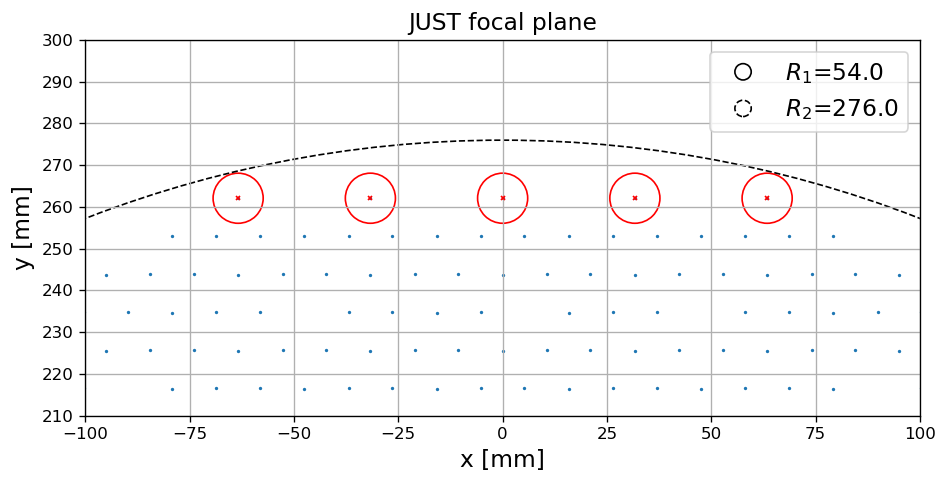

In [18]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.scatter(df_v2["x"], df_v2["y"], s=1.0)
circle1 = Circle((0.0, 0.0), r0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0:.1f}")
circle2 = Circle((0.0, 0.0), r1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={r1:.1f}")
ax.plot(x_sel_up, y_sel_up, "x", ms=2.5, color="red")

for i in range(len(x_sel_up)):
    fiber_circle = Circle((x_sel_up[i], y_sel_up[i]), 6.0, fill=False, color='red', ls='-', alpha=1.0)
    ax.add_patch(fiber_circle)


ax.set_xlim([-100, 100])
ax.set_ylim([210, 300])

ax.add_patch(circle1)
ax.add_patch(circle2)
ax.set_aspect("equal", adjustable="box") 
ax.set_xlabel("x [mm]", fontsize=14)
ax.set_ylabel("y [mm]", fontsize=14)
#ax.legend(fontsize=14)
ax.legend(handler_map={Circle: HandlerCircle()}, fontsize=14)
ax.set_title("JUST focal plane", fontsize=14)
ax.grid()
plt.tight_layout()

## check the lower part of the outer circle

[-21.041092 -10.641092  10.641092  21.041092] [-268.2308 -268.2308 -268.2308 -268.2308]


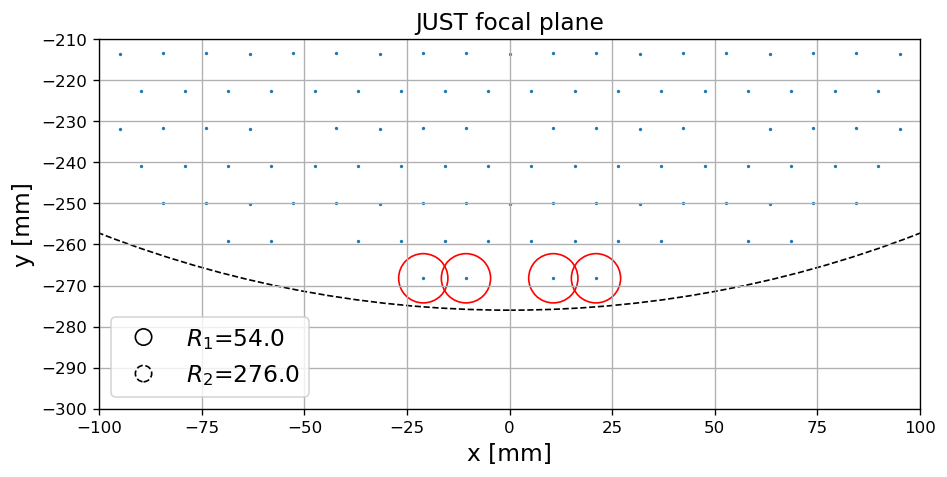

In [19]:
ymin_id = np.argmin(df_v2["y"])
sel_id = (np.abs(df_v2["y"] - df_v2["y"][ymin_id])<1.e-2)
x_sel_low, y_sel_low = df_v2["x"][sel_id], df_v2["y"][sel_id]
print(x_sel_low, y_sel_low)

fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.scatter(df_v2["x"], df_v2["y"], s=1.0)
circle1 = Circle((0.0, 0.0), r0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0:.1f}")
circle2 = Circle((0.0, 0.0), r1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={r1:.1f}")
ax.plot(x_sel_up, y_sel_up, "x", ms=2.5, color="red")

for i in range(len(x_sel_low)):
    fiber_circle = Circle((x_sel_low[i], y_sel_low[i]), 6.0, fill=False, color='red', ls='-', alpha=1.0)
    ax.add_patch(fiber_circle)


ax.set_xlim([-100, 100])
ax.set_ylim([-300, -210])

ax.add_patch(circle1)
ax.add_patch(circle2)
ax.set_aspect("equal", adjustable="box") 
ax.set_xlabel("x [mm]", fontsize=14)
ax.set_ylabel("y [mm]", fontsize=14)
#ax.legend(fontsize=14)
ax.legend(handler_map={Circle: HandlerCircle()}, fontsize=14)
ax.set_title("JUST focal plane", fontsize=14)
ax.grid()
plt.tight_layout()

## check the inner circle

In [20]:
R_fiber_array = (df_v2["x"]**2.0 + df_v2["y"]**2.0)**0.5
R_fiber_min_id = np.argmin(R_fiber_array)
R_fiber_min = R_fiber_array[R_fiber_min_id]

sel_id = (np.abs(R_fiber_array - R_fiber_min)<2.0)
x_sel_3, y_sel_3 = df_v2["x"][sel_id], df_v2["y"][sel_id]
print(x_sel_3, y_sel_3)

[-58.18044  -58.18044  -47.535305 -42.335304 -15.845135 -10.645135
  15.845135  10.645135  47.535305  42.335304  58.18044   58.18044 ] [-21.298615  15.294172 -39.73629   42.738514 -58.032585  61.034805
 -58.032585  61.034805 -39.73629   42.738514 -21.298615  15.294172]


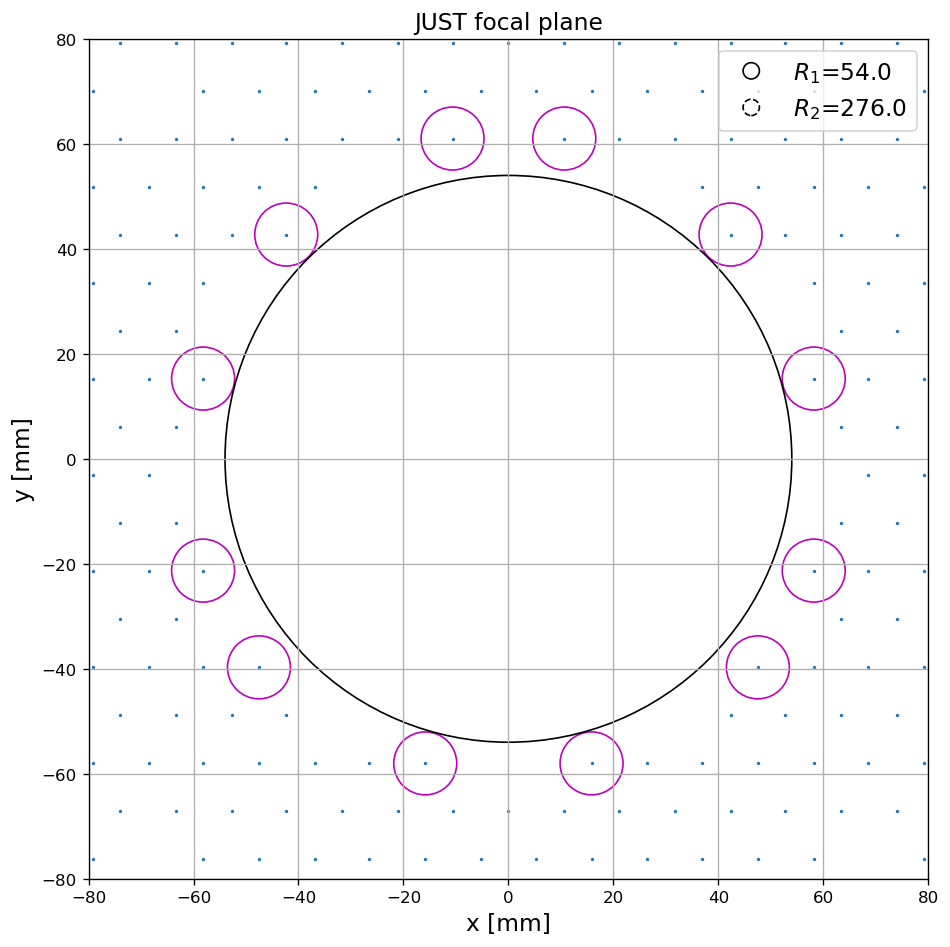

In [24]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.scatter(df_v2["x"], df_v2["y"], s=1.0)

#r0_p = 54.0
circle1 = Circle((0.0, 0.0), r0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0:.1f}")
#circle1 = Circle((0.0, 0.0), r0_p, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={r0_p:.1f}")
circle2 = Circle((0.0, -3.0), r1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={r1:.1f}")

for i in range(len(x_sel_3)):
    fiber_circle_3 = Circle((x_sel_3[i], y_sel_3[i]), 6.0, fill=False, color='m', ls='-', alpha=1.0)
    ax.add_patch(fiber_circle_3)


ax.set_xlim([-80, 80])
ax.set_ylim([-80, 80])

ax.add_patch(circle1)
ax.add_patch(circle2)
ax.set_aspect("equal", adjustable="box") 
ax.set_xlabel("x [mm]", fontsize=14)
ax.set_ylabel("y [mm]", fontsize=14)
#ax.legend(fontsize=14)
ax.legend(handler_map={Circle: HandlerCircle()}, fontsize=14, loc="upper right")
ax.set_title("JUST focal plane", fontsize=14)
ax.grid()
plt.tight_layout()

## projection on sky

In [22]:
x_deg = df_v2['x']*1.e3/platescale/3600
y_deg = df_v2['y']*1.e3/platescale/3600

y_cen_deg = -3.0*1.e3/platescale/3600
print(y_cen_deg)

-0.006510416666666667


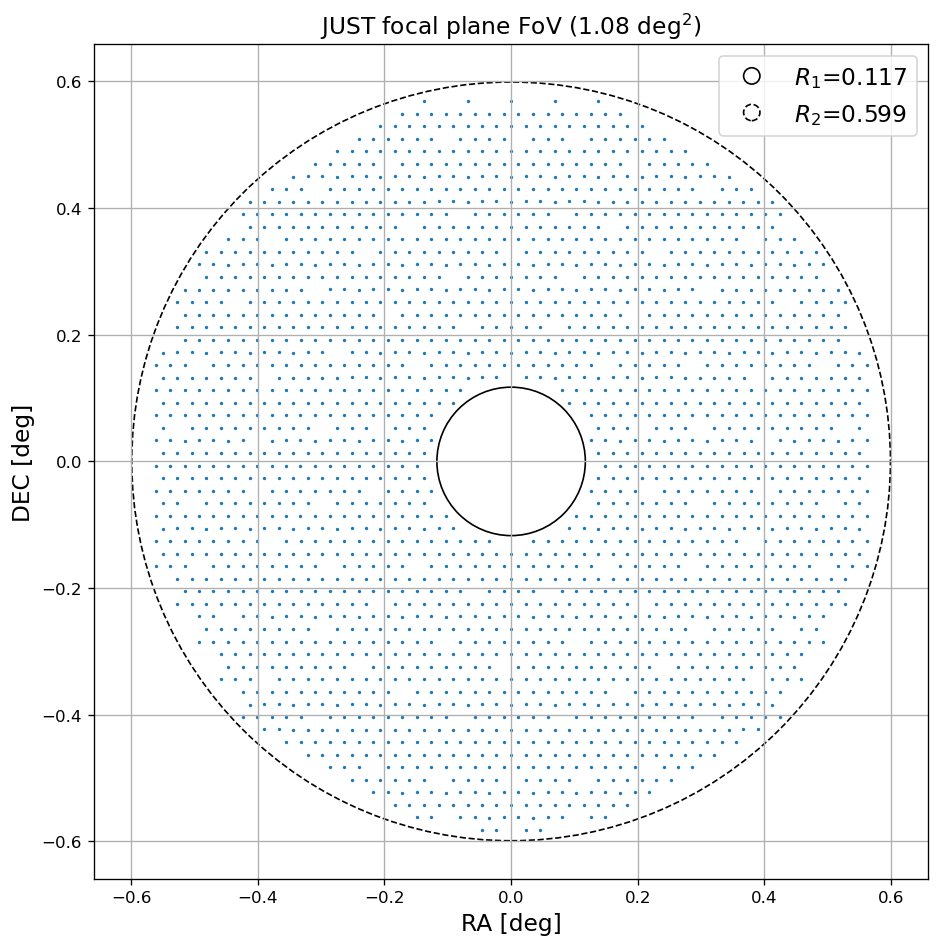

In [25]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=120)
ax.scatter(x_deg, y_deg, s=1.0)

circle1 = Circle((0.0, 0.0), deg0, fill=False, color='k', ls='-', alpha=1.0, label=f"$R_1$={deg0:.3f}")
circle2 = Circle((0.0, 0.0), deg1, fill=False, color='k', ls='--', alpha=1.0, label=f"$R_2$={deg1:.3f}")
ax.add_patch(circle1)
ax.add_patch(circle2)
ax.set_aspect('equal', adjustable='box') 
ax.set_xlabel("RA [deg]", fontsize=14)
ax.set_ylabel("DEC [deg]", fontsize=14)
ax.legend(handler_map={Circle: HandlerCircle()}, fontsize=14)
ax.set_title(f"JUST focal plane FoV ({FoV:.2f} deg$^2$)", fontsize=14)
ax.grid()
plt.tight_layout()
plt.savefig("./just_focalplane_radec.png", bbox_inches='tight')